# STAT 236 — How many BERT dimensions does sentiment classification need?

**Data:** Amazon Polarity (binary sentiment), balanced sample of 20k train / 10k test.

**Representation:** frozen `bert-base-uncased`, masked mean pooling → 768-d embedding per review.

**Question:** if we keep only *k* of the 768 dimensions, how much accuracy do we lose — and does
*supervised* selection (L1) beat *random* selection and PCA?

| Step | What happens | Saved to |
|---|---|---|
| 0 | Settings | – |
| 1 | Sample & clean data | `data/*.parquet` |
| 2 | Extract frozen-BERT embeddings (**needs GPU**) | `embeddings/<tag>/*.npy` |
| EDA | Token lengths, coordinate spread & correlation, PCA, label signal | `results/<tag>/eda/` |
| 3 | Baseline + random / L1 / PCA for each k | `results/<tag>/*.csv` |
| 4 | Plot performance vs k | `results/<tag>/performance_vs_k.png` |

In [ ]:
%pip install -q transformers datasets pyarrow

## Step 0 · Settings

In [2]:
from pathlib import Path
import json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# ---------- run mode ----------
EMB_LIMIT = None     # None = use all sampled texts; a number = only the first N per split (smoke test)
QUICK = False        # True = 3 random seeds & 3 CV folds (fast check); False = full experiment

# ---------- paths ----------
ROOT = Path(".")
DATA_DIR = ROOT / "data"
TAG = "full" if EMB_LIMIT is None else f"limit{EMB_LIMIT}"   # keeps smoke-test files separate
EMB_DIR = ROOT / "embeddings" / TAG
RESULTS_DIR = ROOT / "results" / TAG

# ---------- data ----------
DATASET_NAME = "fancyzhx/amazon_polarity"   # columns: label, title, content
N_TRAIN, N_TEST = 20_000, 10_000            # balanced 50/50
DATA_SEED = 0

# ---------- embeddings ----------
MODEL_NAME = "bert-base-uncased"            # frozen; hidden size 768
MAX_LEN = 256                               # tokens; longer texts are truncated
BATCH_SIZE = 64

# ---------- experiments ----------
# Original grid (25, 50, 100, 200, 400), extended down to k = 1 and with geometric midpoints
# (75, 150, 300) where the curves change most. The full 768 dims is the baseline.
K_LIST = [1, 2, 5, 10, 25, 50, 75, 100, 150, 200, 300, 400]
LABEL_K = [1, 2, 5, 10, 25, 50, 100, 200, 400]   # k values that get a text label on plots
N_RANDOM_SEEDS = 3 if QUICK else 20
CV_FOLDS = 3 if QUICK else 5
L2_CS = np.logspace(-4, 1, 11)              # C grid for the downstream L2 classifier
L1_CS = np.logspace(-4, 0, 33)              # C path for L1 selection (small C = sparser); dense so nearby k don't share a C
EXP_SEED = 42

for d in (DATA_DIR, EMB_DIR, RESULTS_DIR):
    d.mkdir(parents=True, exist_ok=True)
print(f"run tag = {TAG}, QUICK = {QUICK}, sklearn {sklearn.__version__}")

run tag = full, QUICK = False, sklearn 1.6.1


## Step 1 · Sample and clean the data
- Join `title + content` into one text field and normalise whitespace.
- Drop empty texts and duplicates; remove any test review that also appears in train.
- Draw a **balanced** sample (equal count per class), with a fixed seed.

In [3]:
def clean(df: pd.DataFrame) -> pd.DataFrame:
    title = df["title"].fillna("").str.strip()
    content = df["content"].fillna("").str.strip()
    # Add ". " after the title unless it already ends in punctuation (or is empty).
    sep = np.where(title.str.contains(r"[.!?]$", regex=True) | (title == ""), " ", ". ")
    text = (title + sep + content).str.replace(r"\s+", " ", regex=True).str.strip()
    out = pd.DataFrame({"text": text, "label": df["label"].astype(int)})
    out = out[out["text"].str.len() > 0]
    return out.drop_duplicates(subset="text").reset_index(drop=True)


def draw_pool(split, n: int, rng) -> pd.DataFrame:
    # Random pool of 3n rows, so we never convert all 3.6M rows to pandas.
    idx = rng.choice(len(split), size=min(len(split), 3 * n), replace=False)
    return split.select(np.sort(idx)).to_pandas()


def stratified_sample(df: pd.DataFrame, n: int, seed: int) -> pd.DataFrame:
    per_class = n // df["label"].nunique()
    counts = df["label"].value_counts()
    if (counts < per_class).any():
        raise ValueError(f"Not enough rows per class for {per_class} each: {counts.to_dict()}")
    sampled = df.groupby("label", group_keys=False).sample(n=per_class, random_state=seed)
    return sampled.sample(frac=1, random_state=seed).reset_index(drop=True)

In [4]:
train_path, test_path = DATA_DIR / "train.parquet", DATA_DIR / "test.parquet"

if train_path.exists() and test_path.exists():
    print("Loading cached sample from", DATA_DIR)
    train_df, test_df = pd.read_parquet(train_path), pd.read_parquet(test_path)
else:
    from datasets import load_dataset
    ds = load_dataset(DATASET_NAME)
    rng = np.random.default_rng(DATA_SEED)
    train_pool = clean(draw_pool(ds["train"], N_TRAIN, rng))
    test_pool = clean(draw_pool(ds["test"], N_TEST, rng))
    test_pool = test_pool[~test_pool["text"].isin(set(train_pool["text"]))]   # no train/test overlap
    train_df = stratified_sample(train_pool, N_TRAIN, DATA_SEED)
    test_df = stratified_sample(test_pool, N_TEST, DATA_SEED)
    train_df.to_parquet(train_path, index=False)
    test_df.to_parquet(test_path, index=False)

for name, df in [("train", train_df), ("test", test_df)]:
    words = df["text"].str.split().str.len()
    print(f"{name}: n={len(df)}, labels={df['label'].value_counts().sort_index().tolist()}, "
          f"words median={words.median():.0f}, p95={words.quantile(.95):.0f}")
train_df.head()

README.md:   0%|          | 0.00/6.81k [00:00<?, ?B/s]

amazon_polarity/train-00000-of-00004.par(…): reconstructing file:   0%|          |  0.00B /  260MB            

amazon_polarity/train-00000-of-00004.par(…): downloading bytes:           |  0.00B            

amazon_polarity/train-00001-of-00004.par(…): reconstructing file:   0%|          |  0.00B /  258MB            

amazon_polarity/train-00001-of-00004.par(…): downloading bytes:           |  0.00B            

amazon_polarity/train-00002-of-00004.par(…): reconstructing file:   0%|          |  0.00B /  255MB            

... (5 outputs left out)

Generating train split:   0%|          | 0/3600000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/400000 [00:00<?, ? examples/s]

train: n=20000, labels=[10000, 10000], words median=70, p95=161
test: n=10000, labels=[5000, 5000], words median=69, p95=160


,text,label
0,Absolutely delicious smoke. I received this co...,1
1,DEAD IN LESS THAN 3 WEEKS !!! Bought as a repl...,0
2,Excellent re-telling of The Iliad for children...,1
3,Classic. This is real Gospel. It makes me feel...,1
4,"How BAD is this?? This is dreadful. Boring, sl...",0


## Step 2 · Extract frozen-BERT embeddings
- `model.eval()` + `torch.no_grad()`: the transformer is never updated.
- **Masked mean pooling:** average the last-layer token vectors, ignoring padding.
- Texts longer than `MAX_LEN` tokens are truncated; we record how many (report this).
- Embeddings are saved to disk, so this expensive step runs only once.

In [5]:
import torch
from transformers import AutoModel, AutoTokenizer

def get_device():
    if torch.cuda.is_available():
        return torch.device("cuda")
    return torch.device("cpu")


def pool(last_hidden, attention_mask):
    # Masked mean: average the token vectors, ignoring padding.
    mask = attention_mask.unsqueeze(-1).to(last_hidden.dtype)
    return (last_hidden * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1e-9)


@torch.no_grad()
def embed(texts, tokenizer, model, device):
    out = []
    use_amp = device.type == "cuda"
    for start in range(0, len(texts), BATCH_SIZE):
        batch = texts[start:start + BATCH_SIZE]
        enc = tokenizer(batch, padding=True, truncation=True, max_length=MAX_LEN,
                        return_tensors="pt").to(device)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            hidden = model(**enc).last_hidden_state
        out.append(pool(hidden, enc["attention_mask"]).float().cpu().numpy())
        if (start // BATCH_SIZE) % 50 == 0:
            print(f"  {min(start + BATCH_SIZE, len(texts))}/{len(texts)}", flush=True)
    return np.concatenate(out, axis=0)


def token_length_stats(texts, tokenizer):
    lengths = np.array([len(ids) for ids in tokenizer(texts, truncation=False, verbose=False)["input_ids"]])
    return {"median": float(np.median(lengths)), "p95": float(np.percentile(lengths, 95)),
            "max": int(lengths.max()), "frac_truncated": float((lengths > MAX_LEN).mean())}

In [6]:
emb_files = {s: (EMB_DIR / f"X_{s}.npy", EMB_DIR / f"y_{s}.npy") for s in ["train", "test"]}

if all(x.exists() and y.exists() for x, y in emb_files.values()):
    print("Loading cached embeddings from", EMB_DIR)
else:
    device = get_device()
    print(f"Device: {device}  |  model: {MODEL_NAME}  |  max_len={MAX_LEN}  |  pooling=masked mean")
    if device.type == "cpu" and EMB_LIMIT is None:
        print("WARNING: no GPU found — the full run will take hours on CPU.")
    tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
    model = AutoModel.from_pretrained(MODEL_NAME).to(device).eval()
    meta = {"model": MODEL_NAME, "max_len": MAX_LEN, "pooling": "masked mean",
            "hidden_size": model.config.hidden_size, "token_stats": {}}

    for split, df in [("train", train_df), ("test", test_df)]:
        if EMB_LIMIT:
            df = df.iloc[:EMB_LIMIT]
        texts = df["text"].tolist()
        meta["token_stats"][split] = token_length_stats(texts, tokenizer)
        print(f"[{split}] n={len(texts)}  tokens: {meta['token_stats'][split]}")
        t0 = time.time()
        X = embed(texts, tokenizer, model, device)
        print(f"[{split}] embeddings {X.shape} in {time.time() - t0:.1f}s")
        np.save(emb_files[split][0], X.astype(np.float32))
        np.save(emb_files[split][1], df["label"].to_numpy())
    (EMB_DIR / "meta.json").write_text(json.dumps(meta, indent=2))
    del model; torch.cuda.empty_cache() if torch.cuda.is_available() else None

X_tr, y_tr = np.load(emb_files["train"][0]), np.load(emb_files["train"][1])
X_te, y_te = np.load(emb_files["test"][0]), np.load(emb_files["test"][1])
print("X_train", X_tr.shape, "| X_test", X_te.shape)

Device: cuda  |  model: bert-base-uncased  |  max_len=256  |  pooling=masked mean


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[train] n=20000  tokens: {'median': 91.0, 'p95': 208.0, 'max': 484, 'frac_truncated': 0.0017}
  64/20000
  3264/20000
  6464/20000
  9664/20000
  12864/20000
  16064/20000
  19264/20000
[train] embeddings (20000, 768) in 72.5s
[test] n=10000  tokens: {'median': 90.0, 'p95': 206.0, 'max': 319, 'frac_truncated': 0.0018}
  64/10000
  3264/10000
  6464/10000
  9664/10000
[test] embeddings (10000, 768) in 39.8s
X_train (20000, 768) | X_test (10000, 768)


## EDA · Text and embedding properties
Uses only the cached sample (Step 1) and embeddings (Step 2). Every number worth quoting in the
report is collected in `eda` and saved to `results/<tag>/eda/eda_summary.json`; figures go to the same folder.

| Figure | Question it answers | Why it matters for the report |
|---|---|---|
| 1 · Token lengths | How long are reviews? How many hit `MAX_LEN`? Do classes differ in length? | Justifies `MAX_LEN = 256`; checks length isn't a shortcut for the label |
| 2a · Coordinate spread | Are all 768 coordinates on a similar scale, or do a few dominate? | Why we standardise before L1 / PCA (BERT is known to have a few "outlier" dimensions) |
| 2b · Coordinate correlation | How redundant are the coordinates with each other? | Explains why random subsets already work fairly well |
| 2c · Label signal per coordinate | Is sentiment carried by a few coordinates or spread over many? | Context for "sparse" vs "distributed" interpretation |
| 3a · PCA explained variance | How many components hold most of the variance? | Effective dimensionality of the embedding |
| 3b · Label signal per PC | Do high-variance directions carry sentiment? | Context for why unsupervised PCA competes with supervised L1 |

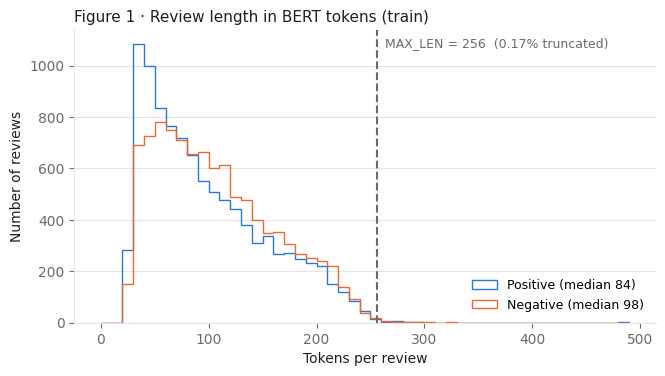

In [7]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

EDA_DIR = RESULTS_DIR / "eda"
EDA_DIR.mkdir(parents=True, exist_ok=True)
BLUE, ORANGE = "#2a78d6", "#eb6834"            # positive / negative (fixed throughout)
INK, MUTED, GRID = "#1f1f1e", "#6b6a63", "#e6e5e0"
CLASSES = [(1, "Positive", BLUE), (0, "Negative", ORANGE)]
eda = {}                                       # numbers to quote in the report

def style_ax(ax, title, xlabel, ylabel):
    ax.set_title(title, loc="left", fontsize=11, color=INK)
    ax.set_xlabel(xlabel, color=INK); ax.set_ylabel(ylabel, color=INK)
    ax.grid(axis="y", color=GRID, lw=0.8); ax.set_axisbelow(True)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    for side in ["left", "bottom"]:
        ax.spines[side].set_color(GRID)
    ax.tick_params(colors=MUTED)

def save(fig, name):
    fig.savefig(EDA_DIR / name, dpi=200, bbox_inches="tight", facecolor="white")
    plt.show()

# ---------------- Figure 1: token lengths (BERT word-piece tokens, incl. [CLS]/[SEP])
tok = AutoTokenizer.from_pretrained(MODEL_NAME)
eda_train = train_df.iloc[:len(X_tr)]          # same rows that were embedded
tok_len = np.array([len(ids) for ids in tok(eda_train["text"].tolist(), truncation=False, verbose=False)["input_ids"]])
lab = eda_train["label"].to_numpy()

eda["tokens_median"] = float(np.median(tok_len))
eda["frac_truncated_at_max_len"] = float((tok_len > MAX_LEN).mean())
for c, name, _ in CLASSES:
    eda[f"tokens_median_{name.lower()}"] = float(np.median(tok_len[lab == c]))

fig, ax = plt.subplots(figsize=(7.5, 3.8))
bins = np.arange(0, max(tok_len.max(), MAX_LEN) + 10, 10)
for c, name, color in CLASSES:
    ax.hist(tok_len[lab == c], bins=bins, histtype="step", lw=2, color=color,
            label=f"{name} (median {np.median(tok_len[lab == c]):.0f})")
ax.axvline(MAX_LEN, color=MUTED, lw=1.5, ls="--")
ax.annotate(f"MAX_LEN = {MAX_LEN}  ({100 * eda['frac_truncated_at_max_len']:.2f}% truncated)",
            xy=(MAX_LEN, 1), xycoords=("data", "axes fraction"), xytext=(6, -12),
            textcoords="offset points", fontsize=9, color=MUTED)
style_ax(ax, "Figure 1 · Review length in BERT tokens (train)", "Tokens per review", "Number of reviews")
ax.legend(frameon=False, fontsize=9)
save(fig, "fig1_token_lengths.png")

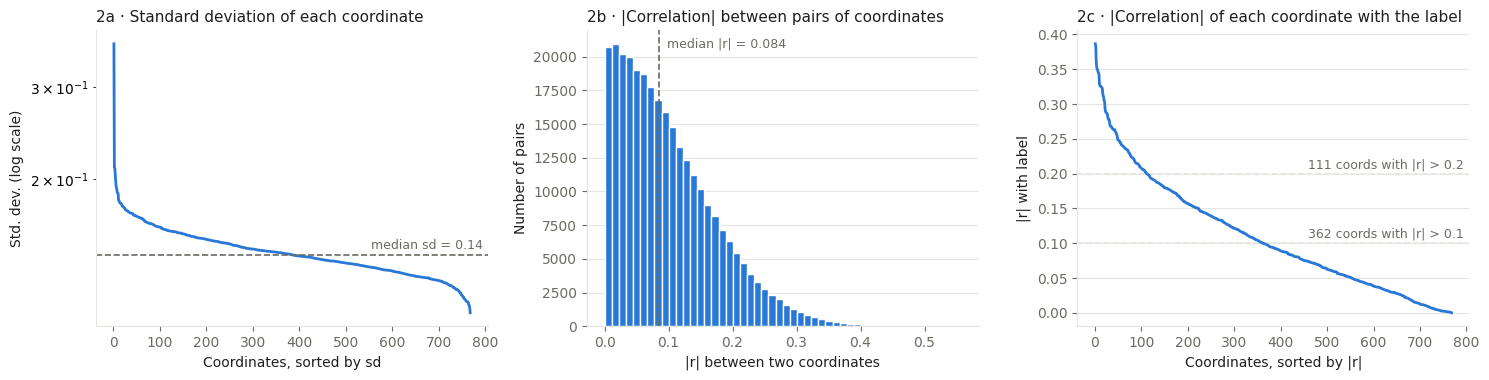

In [8]:
# ---------------- Figure 2: what do the 768 raw coordinates look like?
n, d = X_tr.shape
coord_sd = X_tr.std(axis=0)
coord_mean = X_tr.mean(axis=0)

# Pairwise correlation between coordinates (768 x 768); keep the upper triangle only.
corr = np.corrcoef(X_tr, rowvar=False)
abs_offdiag = np.abs(corr[np.triu_indices(d, k=1)])

# Univariate label signal: Pearson (= point-biserial) correlation of each coordinate with the label.
z = (X_tr - coord_mean) / coord_sd
yc = (y_tr - y_tr.mean()) / y_tr.std()
r_label = z.T @ yc / n
abs_r = np.abs(r_label)

outlier = coord_sd > 5 * np.median(coord_sd)
eda["coord_sd_max_over_median"] = float(coord_sd.max() / np.median(coord_sd))
eda["n_outlier_coords_sd_gt_5x_median"] = int(outlier.sum())
eda["coord_corr_abs_median"] = float(np.median(abs_offdiag))
eda["label_corr_abs_max"] = float(abs_r.max())
eda["n_coords_label_corr_abs_gt_0.1"] = int((abs_r > 0.1).sum())

fig, axes = plt.subplots(1, 3, figsize=(15, 3.9))

ax = axes[0]
ranks = np.arange(1, d + 1)
ax.plot(ranks, np.sort(coord_sd)[::-1], color=BLUE, lw=2)
ax.set_yscale("log")
ax.axhline(np.median(coord_sd), color=MUTED, lw=1.2, ls="--")
ax.annotate(f"median sd = {np.median(coord_sd):.2f}", xy=(1, np.median(coord_sd)),
            xycoords=("axes fraction", "data"), xytext=(-4, 4), textcoords="offset points",
            ha="right", fontsize=9, color=MUTED)
style_ax(ax, "2a · Standard deviation of each coordinate", "Coordinates, sorted by sd", "Std. dev. (log scale)")

ax = axes[1]
ax.hist(abs_offdiag, bins=50, color=BLUE, edgecolor="white", lw=0.5)
ax.axvline(np.median(abs_offdiag), color=MUTED, lw=1.2, ls="--")
ax.annotate(f"median |r| = {np.median(abs_offdiag):.3f}", xy=(np.median(abs_offdiag), 1),
            xycoords=("data", "axes fraction"), xytext=(6, -12), textcoords="offset points",
            fontsize=9, color=MUTED)
style_ax(ax, "2b · |Correlation| between pairs of coordinates", "|r| between two coordinates", "Number of pairs")

ax = axes[2]
ax.plot(ranks, np.sort(abs_r)[::-1], color=BLUE, lw=2)
for thr in (0.1, 0.2):
    m = int((abs_r > thr).sum())
    ax.axhline(thr, color=GRID, lw=1.2, ls="--", zorder=0)
    ax.annotate(f"{m} coords with |r| > {thr}", xy=(1, thr), xycoords=("axes fraction", "data"),
                xytext=(-4, 4), textcoords="offset points", ha="right", fontsize=9, color=MUTED)
style_ax(ax, "2c · |Correlation| of each coordinate with the label", "Coordinates, sorted by |r|", "|r| with label")

fig.tight_layout()
save(fig, "fig2_coordinates.png")

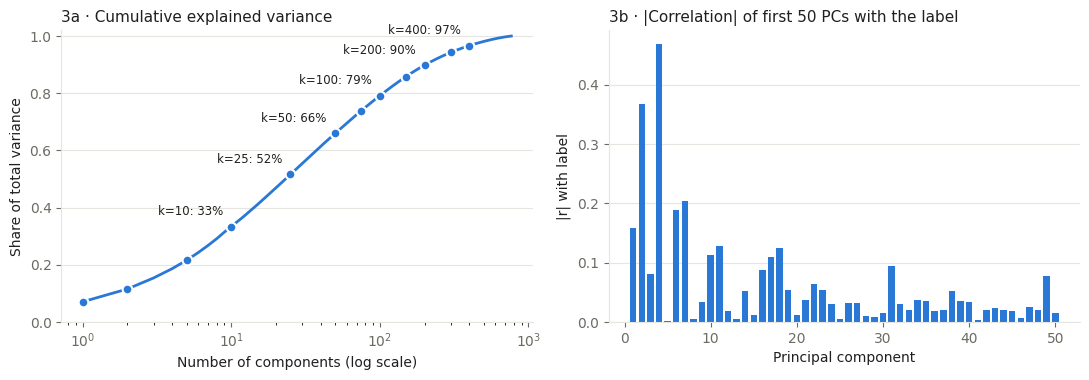

In [9]:
# ---------------- Figure 3: PCA on standardised train embeddings
Xs_eda = StandardScaler().fit_transform(X_tr)
pca_full = PCA(random_state=EXP_SEED).fit(Xs_eda)
evr = pca_full.explained_variance_ratio_
cum = np.cumsum(evr)
n_pc_show = 50
Z = pca_full.transform(Xs_eda)[:, :n_pc_show]
r_pc = np.array([np.corrcoef(Z[:, j], y_tr)[0, 1] for j in range(n_pc_show)])
abs_r_pc = np.abs(r_pc)

for frac in (0.8, 0.9):
    eda[f"n_pcs_for_{int(frac * 100)}pct_variance"] = int(np.searchsorted(cum, frac) + 1)
eda["pcs_most_label_correlated"] = [f"PC{j + 1} (|r|={abs_r_pc[j]:.2f})" for j in np.argsort(-abs_r_pc)[:3]]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.9))

ax = axes[0]
ax.plot(np.arange(1, len(cum) + 1), cum, color=BLUE, lw=2)
ks = [k for k in K_LIST if k <= len(cum)]
ax.plot(ks, cum[np.array(ks) - 1], ls="none", marker="o", ms=7, color=BLUE, mec="white", mew=1.5)
for k in [k for k in ks if k in LABEL_K and k >= 10]:
    ax.annotate(f"k={k}: {100 * cum[k - 1]:.0f}%", xy=(k, cum[k - 1]), xytext=(-6, 6),
                textcoords="offset points", ha="right", va="bottom", fontsize=8.5, color=INK)
ax.set_xscale("log"); ax.set_ylim(0, 1.02)
style_ax(ax, "3a · Cumulative explained variance", "Number of components (log scale)", "Share of total variance")

ax = axes[1]
ax.bar(np.arange(1, n_pc_show + 1), abs_r_pc, color=BLUE, width=0.75)
style_ax(ax, f"3b · |Correlation| of first {n_pc_show} PCs with the label", "Principal component", "|r| with label")

fig.tight_layout()
save(fig, "fig3_pca.png")

In [10]:
(EDA_DIR / "eda_summary.json").write_text(json.dumps(eda, indent=2))
print("Saved figures and eda_summary.json to", EDA_DIR)
pd.Series(eda, name="value").to_frame()

Saved figures and eda_summary.json to results/full/eda


,value
tokens_median,91.0
frac_truncated_at_max_len,0.0017
tokens_median_positive,84.0
tokens_median_negative,98.0
coord_sd_max_over_median,2.542642
n_outlier_coords_sd_gt_5x_median,0
coord_corr_abs_median,0.084484
label_corr_abs_max,0.386468
n_coords_label_corr_abs_gt_0.1,362
n_pcs_for_80pct_variance,105


## Step 3 · Experiments
Every decision (scaling, which coordinates, PCA) is made on **train only**; test is scored once.

| Method | How the k dimensions are chosen |
|---|---|
| `full` | all 768 (baseline) |
| `random` | k coordinates at random, repeated over several seeds |
| `l1` | L1 logistic regression on train; keep the k coordinates with largest \|coef\| |
| `pca` | first k principal components (linear combinations, not coordinate subsets) |

**Same downstream classifier for all:** StandardScaler → L2 logistic regression, C tuned by stratified CV on train.

**L1 rule:** fit L1 logistic regression along a path of C values; for each k use the *smallest* C
(strongest penalty) that leaves ≥ k nonzero coefficients, then keep the k largest |coef|.

In [11]:
SKLEARN_GE_18 = tuple(int(p) for p in sklearn.__version__.split(".")[:2]) >= (1, 8)

def fit_and_score(Xa, Xb):
    # Scale -> L2 logistic regression (default penalty), C chosen by CV on train; score once on test.
    pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))
    cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=EXP_SEED)
    search = GridSearchCV(pipe, {"logisticregression__C": L2_CS}, cv=cv, scoring="accuracy", n_jobs=-1)
    search.fit(Xa, y_tr)
    pred = search.predict(Xb)
    return {"accuracy": accuracy_score(y_te, pred), "macro_f1": f1_score(y_te, pred, average="macro"),
            "cv_accuracy": search.best_score_, "best_C": search.best_params_["logisticregression__C"]}


def l1_logreg(c):
    # sklearn >= 1.8 deprecates `penalty`; l1_ratio=1 means pure L1.
    if SKLEARN_GE_18:
        return LogisticRegression(l1_ratio=1.0, C=c, solver="liblinear", max_iter=3000, random_state=EXP_SEED)
    return LogisticRegression(penalty="l1", C=c, solver="liblinear", max_iter=3000, random_state=EXP_SEED)


def l1_path(X, y):
    path = []
    for c in L1_CS:
        coef = l1_logreg(c).fit(X, y).coef_
        importance = np.abs(coef).sum(axis=0)          # binary: one row; multiclass: sum over classes
        path.append({"C": float(c), "importance": importance, "n_nonzero": int((importance > 0).sum())})
    return path


def l1_select(path, k):
    for step in path:                                  # ordered from small C (sparse) to large C
        if step["n_nonzero"] >= k:
            break
    else:
        print(f"  warning: no C on the path gives {k} nonzero coefs; using the largest C")
    return np.sort(np.argsort(-step["importance"], kind="stable")[:k]), step

In [12]:
d = X_tr.shape[1]
k_list = [k for k in K_LIST if k < min(d, len(X_tr))]   # PCA can't have more components than samples
print(f"d = {d}, k = {k_list}, random seeds = {N_RANDOM_SEEDS}, CV folds = {CV_FOLDS}")

# Standardise once (fit on train) so |L1 coef| and PCA aren't driven by each coordinate's raw scale.
scaler = StandardScaler().fit(X_tr)
Xs_tr, Xs_te = scaler.transform(X_tr), scaler.transform(X_te)

rows = []
def record(method, k, Xa, Xb, seed=None, **extra):
    t0 = time.time()
    res = fit_and_score(Xa, Xb)
    rows.append({"method": method, "k": k, "seed": seed, **res, **extra})
    print(f"  {method:>6}  k={k:<4} seed={seed}  acc={res['accuracy']:.4f}  f1={res['macro_f1']:.4f}  "
          f"C={res['best_C']:.3g}  ({time.time() - t0:.1f}s)", flush=True)

print("\n[full baseline]")
record("full", d, Xs_tr, Xs_te)

print("\n[random coordinates]")
rng = np.random.default_rng(EXP_SEED)
for k in k_list:
    for s in range(N_RANDOM_SEEDS):
        idx = np.sort(rng.choice(d, size=k, replace=False))
        record("random", k, Xs_tr[:, idx], Xs_te[:, idx], seed=s)

print("\n[L1 selection]")
path = l1_path(Xs_tr, y_tr)
print("  C -> #nonzero: " + ", ".join(f"{p['C']:.2g}->{p['n_nonzero']}" for p in path))
for k in k_list:
    idx, step = l1_select(path, k)
    record("l1", k, Xs_tr[:, idx], Xs_te[:, idx], l1_C=step["C"], l1_n_nonzero=step["n_nonzero"])

print("\n[PCA]")
pca = PCA(n_components=max(k_list), random_state=EXP_SEED).fit(Xs_tr)
P_tr, P_te = pca.transform(Xs_tr), pca.transform(Xs_te)
cum_var = np.cumsum(pca.explained_variance_ratio_)
for k in k_list:   # components are ordered, so the first k columns = PCA with k components
    record("pca", k, P_tr[:, :k], P_te[:, :k], pca_explained_var=float(cum_var[k - 1]))

d = 768, k = [1, 2, 5, 10, 25, 50, 75, 100, 150, 200, 300, 400], random seeds = 20, CV folds = 5

[full baseline]
    full  k=768  seed=None  acc=0.9080  f1=0.9080  C=0.01  (63.6s)

[random coordinates]
  random  k=1    seed=0  acc=0.5668  f1=0.5668  C=0.01  (0.5s)
  random  k=1    seed=1  acc=0.6713  f1=0.6713  C=0.1  (1.0s)
  random  k=1    seed=2  acc=0.5413  f1=0.5413  C=0.0001  (0.8s)
  random  k=1    seed=3  acc=0.5659  f1=0.5659  C=0.0001  (0.8s)
  random  k=1    seed=4  acc=0.5224  f1=0.5221  C=0.0001  (0.7s)
  random  k=1    seed=5  acc=0.5074  f1=0.5074  C=0.0001  (0.5s)
  random  k=1    seed=6  acc=0.5103  f1=0.5103  C=0.0001  (0.5s)
  random  k=1    seed=7  acc=0.5714  f1=0.5714  C=0.1  (0.5s)
  random  k=1    seed=8  acc=0.5364  f1=0.5364  C=0.01  (0.5s)
  random  k=1    seed=9  acc=0.5290  f1=0.5289  C=0.00316  (0.5s)
  random  k=1    seed=10  acc=0.5295  f1=0.5293  C=0.0001  (0.5s)
  random  k=1    seed=11  acc=0.5548  f1=0.5548  C=0.001  (0.5s)
  random  k=1    seed=12 

In [ ]:
raw = pd.DataFrame(rows)
summary = (raw.groupby(["method", "k"], as_index=False)
              .agg(n_runs=("accuracy", "size"),
                   acc_mean=("accuracy", "mean"), acc_std=("accuracy", "std"),
                   f1_mean=("macro_f1", "mean"), f1_std=("macro_f1", "std")))
full = summary.loc[summary["method"] == "full"].iloc[0]
summary["acc_loss_vs_full"] = full["acc_mean"] - summary["acc_mean"]
summary["f1_loss_vs_full"] = full["f1_mean"] - summary["f1_mean"]

raw.to_csv(RESULTS_DIR / "results_raw.csv", index=False)
summary.to_csv(RESULTS_DIR / "summary.csv", index=False)
print("Saved to", RESULTS_DIR)
summary.round(4)

## Step 4 · Performance vs number of dimensions

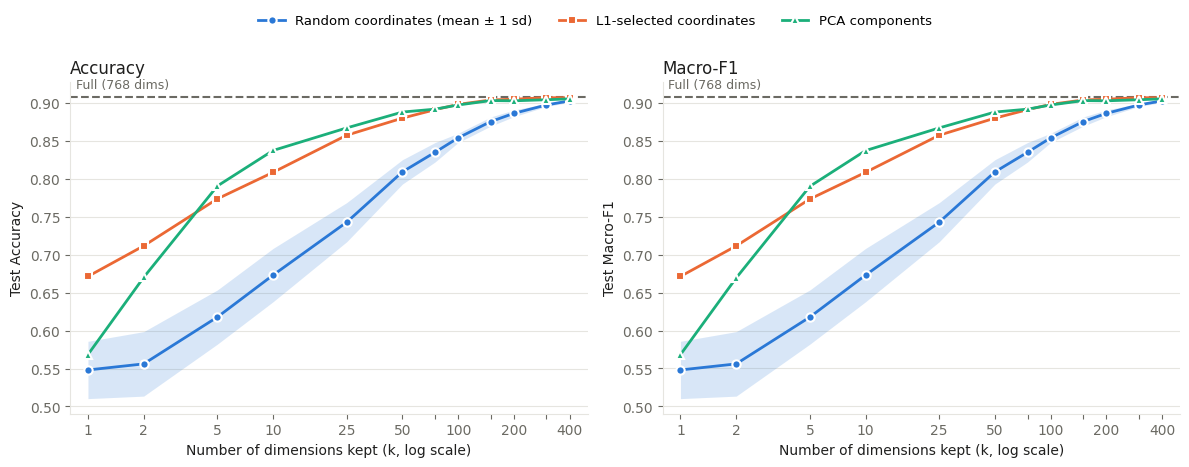

In [14]:
# Fixed colour per method, plus a distinct marker shape so colour isn't the only cue.
STYLE = {
    "random": {"color": "#2a78d6", "marker": "o", "label": "Random coordinates (mean ± 1 sd)"},
    "l1":     {"color": "#eb6834", "marker": "s", "label": "L1-selected coordinates"},
    "pca":    {"color": "#1baf7a", "marker": "^", "label": "PCA components"},
}
INK, MUTED, GRID = "#1f1f1e", "#6b6a63", "#e6e5e0"

def panel(ax, summary, metric, title):
    full = summary.loc[summary["method"] == "full"].iloc[0]
    ax.axhline(full[f"{metric}_mean"], color=MUTED, lw=1.5, ls="--", zorder=1)
    ax.annotate(f"Full ({int(full['k'])} dims)", xy=(0, full[f"{metric}_mean"]),
                xycoords=("axes fraction", "data"), xytext=(4, 4), textcoords="offset points",
                ha="left", va="bottom", fontsize=9, color=MUTED)
    for method, st in STYLE.items():
        s = summary[summary["method"] == method].sort_values("k")
        if s.empty:
            continue
        mean, sd = s[f"{metric}_mean"], s[f"{metric}_std"].fillna(0)
        if method == "random":
            ax.fill_between(s["k"], mean - sd, mean + sd, color=st["color"], alpha=0.18, lw=0, zorder=2)
        ax.plot(s["k"], mean, color=st["color"], lw=2, marker=st["marker"], ms=6,
                mec="white", mew=1.5, label=st["label"], zorder=3)
    ks = sorted(summary.loc[summary["method"] != "full", "k"].unique())
    ax.set_xscale("log"); ax.set_xticks(ks); ax.set_xticklabels([str(k) if k in LABEL_K else "" for k in ks]); ax.minorticks_off()
    ax.set_xlim(ks[0] * 0.8, ks[-1] * 1.25)
    ax.set_xlabel("Number of dimensions kept (k, log scale)", color=INK)
    ax.set_ylabel(f"Test {title}", color=INK)
    ax.set_title(title, loc="left", fontsize=12, color=INK)
    ax.grid(axis="y", color=GRID, lw=0.8)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    for side in ["left", "bottom"]:
        ax.spines[side].set_color(GRID)
    ax.tick_params(colors=MUTED)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
panel(axes[0], summary, "acc", "Accuracy")
panel(axes[1], summary, "f1", "Macro-F1")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=3, frameon=False, fontsize=9.5, bbox_to_anchor=(0.5, 1.02))
fig.tight_layout(rect=(0, 0, 1, 0.93))
fig.savefig(RESULTS_DIR / "performance_vs_k.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()